# Étude de Cas Big Data : Analyse des Accidents de la Route avec PySpark

## Introduction
Cette étude de cas explore les données d'accidents de la route en Australie du Sud. L'objectif est de manipuler de larges volumes de données CSV à l'aide d'Apache Spark (via PySpark) en exploitant le calcul parallèle sur notre machine locale. 
Nous utiliserons principalement l'API DataFrame de PySpark, qui permet des manipulations similaires à celles des bases de données relationnelles, mais optimisées pour le Big Data.

In [1]:
from pyspark.sql import SparkSession

# 1. Création de la session Spark en utilisant tous les cœurs de votre machine locale
spark = SparkSession.builder \
    .master("local[*]") \
    .appName("Road Crash Analysis") \
    .getOrCreate()

# Réduction du niveau de log pour garder le notebook propre
spark.sparkContext.setLogLevel('ERROR')
print("Session Spark initialisée !")

# 2. Chargement des fichiers CSV dans un DataFrame
# L'option escape='"' est importante car certains champs de texte dans ce jeu de données contiennent des virgules
crash_df = spark.read.format('csv') \
    .option('header', True) \
    .option('inferSchema', True) \
    .option('escape', '"') \
    .load('./crash_data/*.csv')

# 3. Vérification des données
print(f"Nombre total d'accidents chargés : {crash_df.count()}")
crash_df.printSchema()  # Affiche la structure des colonnes
crash_df.show(5)        # Affiche les 5 premières lignes

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/16 09:13:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Session Spark initialisée !


Nombre total d'accidents chargés : 127672
root
 |-- REPORT_ID: string (nullable = true)
 |-- Stats Area: string (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Postcode: integer (nullable = true)
 |-- LGA Name: string (nullable = true)
 |-- Total Units: integer (nullable = true)
 |-- Total Cas: integer (nullable = true)
 |-- Total Fats: integer (nullable = true)
 |-- Total SI: integer (nullable = true)
 |-- Total MI: integer (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: string (nullable = true)
 |-- Day: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Area Speed: integer (nullable = true)
 |-- Position Type: string (nullable = true)
 |-- Horizontal Align: string (nullable = true)
 |-- Vertical Align: string (nullable = true)
 |-- Other Feat: string (nullable = true)
 |-- Road Surface: string (nullable = true)
 |-- Moisture Cond: string (nullable = true)
 |-- Weather Cond: string (nullable = true)
 |-- DayNight: string (nullable = true

In [2]:
# Analyse avec l'API PySpark DataFrame
import pyspark.sql.functions as F

# Objectif : Trouver le nombre total de décès par type d'accident
print("--- Nombre total de décès par type d'accident ---")
fatalities_by_type = crash_df.groupBy('Crash Type') \
    .agg(F.sum('Total Fats').alias('Total_Fatalities')) \
    .orderBy(F.col('Total_Fatalities').desc())

# On affiche le résultat complet
fatalities_by_type.show(truncate=False)

--- Nombre total de décès par type d'accident ---
+--------------------------+----------------+
|Crash Type                |Total_Fatalities|
+--------------------------+----------------+
|Hit Fixed Object          |245             |
|Head On                   |136             |
|Hit Pedestrian            |109             |
|Roll Over                 |93              |
|Right Angle               |82              |
|Rear End                  |33              |
|Side Swipe                |30              |
|Right Turn                |26              |
|Hit Parked Vehicle        |10              |
|Hit Animal                |7               |
|Other                     |5               |
|Left Road - Out of Control|3               |
|Hit Object on Road        |2               |
+--------------------------+----------------+



In [3]:
# Analyse avec SparkSQL
# Objectif : Trouver les 5 banlieues (Suburbs) avec le plus d'accidents 
#  en utilisant une syntaxe SQL pure

# 1. On déclare notre DataFrame comme une table virtuelle temporaire
crash_df.createOrReplaceTempView("crash_table")

# 2. On écrit notre requête SQL
top_suburbs_sql = spark.sql("""
    SELECT Suburb, COUNT(REPORT_ID) as Total_Accidents
    FROM crash_table
    WHERE Suburb IS NOT NULL
    GROUP BY Suburb
    ORDER BY Total_Accidents DESC
    LIMIT 5
""")

print("--- Top 5 des banlieues avec le plus d'accidents (Via SparkSQL) ---")
top_suburbs_sql.show()

--- Top 5 des banlieues avec le plus d'accidents (Via SparkSQL) ---
+--------------+---------------+
|        Suburb|Total_Accidents|
+--------------+---------------+
|      ADELAIDE|           5667|
|      PROSPECT|           1591|
|NORTH ADELAIDE|           1444|
|       NORWOOD|           1373|
|  MAWSON LAKES|           1191|
+--------------+---------------+



In [4]:
# Analyse bas niveau avec les RDDs
# Objectif : Compter le nombre d'accidents par jour de la semaine en utilisant l'API bas niveau RDD

# 1. Chargement brut sous forme de lignes de texte
crash_rdd = spark.sparkContext.textFile('./crash_data/*.csv')

# 2. Retrait de l'en-tête (première ligne)
header = crash_rdd.first()
crash_rdd_data = crash_rdd.filter(lambda ligne: ligne != header)

# 3. Fonction pour extraire le jour (13ème colonne, index 12) et créer une paire (Clé, Valeur)
def extract_day(line):
    colonnes = line.split(',')
    # On nettoie les éventuels guillemets
    jour = colonnes[12].replace('"', '')
    return (jour, 1)

# 4. Transformations : Map (crée les paires) et ReduceByKey (additionne les valeurs par jour)
accidents_by_day_rdd = crash_rdd_data.map(extract_day).reduceByKey(lambda a, b: a + b)

print("--- Nombre d'accidents par jour de la semaine (Via RDD) ---")
# L'action collect() ramène les résultats sur le programme principal
for jour, count in accidents_by_day_rdd.collect():
    print(f"{jour}: {count}")

--- Nombre d'accidents par jour de la semaine (Via RDD) ---


[Stage 13:>                                                         (0 + 8) / 8]

Monday: 16932
April: 425
June: 474
January: 380
Sunday: 12350
Thursday: 19805
September: 444
October: 446
November: 484
May: 544
July: 436
August: 517
Wednesday: 19231
Tuesday: 18409
Friday: 20303
Saturday: 15076
February: 442
March: 545
December: 429


/home/urmenus/anaconda3/envs/ml/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


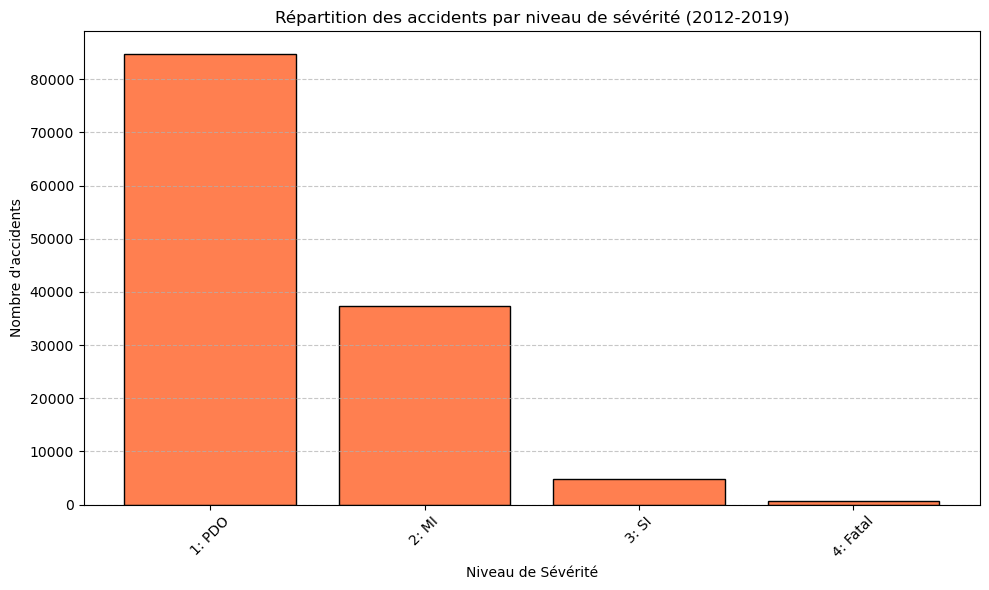

In [5]:
# Analyse et Visualisation
# nous agrégeons avec Spark de manière distribuée, puis nous rapatrions ce petit tableau résumé vers Pandas pour l'afficher graphiquement
import matplotlib.pyplot as plt
import pandas as pd

# Objectif : Visualiser la répartition des accidents par niveau de sévérité

# 1. Agrégation distribuée avec PySpark (très rapide sur de grosses données)
severity_df = crash_df.groupBy('CSEF Severity').count().orderBy('count', ascending=False)

# 2. Conversion en Pandas DataFrame
# QUE sur des données réduites (agrégées) sinon votre machine va saturer !
severity_pd = severity_df.toPandas()

# 3. Tracé du graphique avec Matplotlib
plt.figure(figsize=(10, 6))
plt.bar(severity_pd['CSEF Severity'], severity_pd['count'], color='coral', edgecolor='black')
plt.title("Répartition des accidents par niveau de sévérité (2012-2019)")
plt.xlabel("Niveau de Sévérité")
plt.ylabel("Nombre d'accidents")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Comparaison des méthodes PySpark

PySpark nous offre trois façons de manipuler les données :

1. **Les RDDs (Resilient Distributed Datasets) :** C'est la structure historique et de bas niveau de Spark. Elle demande d'écrire des fonctions Python personnalisées (Map/Reduce). C'est puissant mais verbeux, et Spark ne peut pas optimiser le code Python qu'on lui donne.
2. **Les DataFrames :** C'est l'approche recommandée aujourd'hui. Les données sont structurées en colonnes nommées. Spark utilise un moteur (Catalyst Optimizer) qui optimise automatiquement les requêtes en arrière-plan, ce qui les rend beaucoup plus rapides que les RDDs.
3. **SparkSQL :** Il permet d'utiliser le langage SQL standard en créant des "vues temporaires". C'est idéal pour les analystes de données. En termes de performances, SparkSQL et les DataFrames sont exactement identiques car ils utilisent le même moteur d'optimisation sous le capot.

## Conclusion

Dans cette étude de cas, nous avons mis en pratique les concepts fondamentaux du Big Data avec Apache Spark. Nous avons pu :
* Charger un grand volume de données CSV réparties dans plusieurs fichiers.
* Interroger ces données avec les RDDs, les DataFrames et SparkSQL.
* Constater qu'il est indispensable de réduire et d'agréger les données de manière distribuée avec Spark *avant* de les convertir en objets locaux (Pandas) pour créer des visualisations sans saturer la mémoire de notre machine locale.

PySpark s'avère donc être un outil indispensable pour faire le pont entre le stockage massif (comme HDFS ou de multiples CSV) et l'analyse de données classique !